# E-commerce customer behaviour: a churn model that's too good to be true

**Data:** 350 customers of an online store: gender, age, city, membership tier, total spend, items bought, average rating, discount used, days since last purchase and satisfaction level.

A common analysis defines **churn = more than 30 days since the last purchase** and trains classifiers that reach **~98% accuracy**. This notebook:
1. explores the customers,
2. reproduces the 98% result,
3. audits the data and shows why the number is misleading,
4. re-evaluates honestly.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from common import style
from common.style import BLUE, ORANGE, AQUA, MUTED, SERIES

style.apply()
SEED = 42
raw = pd.read_csv("data/ecommerce_customer_behavior.csv")
raw.columns = ["customer_id", "gender", "age", "city", "membership", "total_spend", "items", "avg_rating",
               "discount", "days_since_purchase", "satisfaction"]
print(raw.shape)
raw.head()

(350, 11)


,customer_id,gender,age,city,membership,total_spend,items,avg_rating,discount,days_since_purchase,satisfaction
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


## 1. Who are the customers?

In [2]:
display(raw.isna().sum()[lambda s: s > 0])
summary = raw.groupby("membership").agg(
    customers=("customer_id", "size"), avg_spend=("total_spend", "mean"), avg_items=("items", "mean"),
    avg_rating=("avg_rating", "mean"), avg_days_since=("days_since_purchase", "mean"),
).reindex(["Gold", "Silver", "Bronze"]).round(1)
summary

satisfaction    2
dtype: int64

,customers,avg_spend,avg_items,avg_rating,avg_days_since
membership,,,,,
Gold,117,1311.1,17.6,4.7,17.9
Silver,117,748.4,11.7,4.1,30.3
Bronze,116,473.4,8.5,3.3,31.6


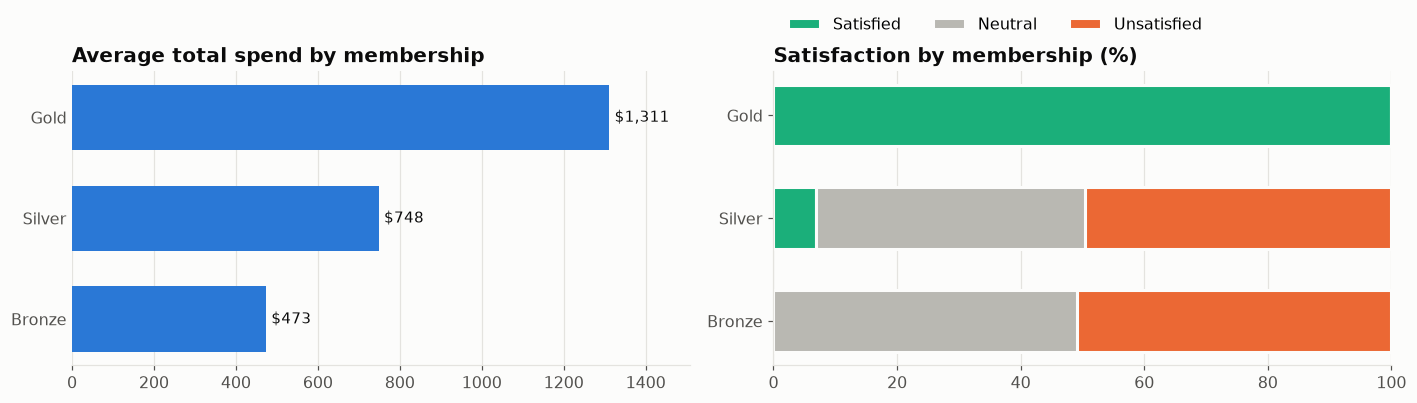

In [3]:
sat = pd.crosstab(raw["membership"], raw["satisfaction"], normalize="index").mul(100).reindex(["Gold", "Silver", "Bronze"])[
    ["Satisfied", "Neutral", "Unsatisfied"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
style.hbar(axes[0], summary.index, summary["avg_spend"], fmt="${:,.0f}")
axes[0].set_title("Average total spend by membership")
left = np.zeros(len(sat))
for col, color in zip(sat.columns, [AQUA, MUTED, ORANGE]):
    axes[1].barh(sat.index[::-1], sat[col][::-1], left=left[::-1], color=color, label=col, height=0.6,
                 edgecolor="#fcfcfb", linewidth=2)
    left += sat[col].values
axes[1].set_title("Satisfaction by membership (%)")
axes[1].legend(loc="lower left", ncols=3, bbox_to_anchor=(0, 1.08))
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
style.save(fig, "membership_overview")
plt.show()

## 2. Reproducing the 98%

In [4]:
df = raw.copy()
df["churn"] = (df["days_since_purchase"] > 30).astype(int)
df["satisfaction"] = df["satisfaction"].fillna("Neutral")
features = ["gender", "age", "city", "membership", "total_spend", "items", "avg_rating", "discount", "satisfaction"]
X = pd.get_dummies(df[features], drop_first=True).astype(float)
y = df["churn"]
print(f"Churn rate: {y.mean():.1%}")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=3, random_state=SEED),
}
naive = {name: m.fit(X_tr, y_tr).score(X_te, y_te) for name, m in models.items()}
for name, acc in naive.items():
    print(f"{name}: {acc:.1%} test accuracy (random 70/30 split)")

Churn rate: 35.4%


Logistic regression: 98.1% test accuracy (random 70/30 split)
Random forest: 98.1% test accuracy (random 70/30 split)


## 3. Data audit

### 3a. Half the rows are duplicates

In [5]:
dup_mask = df.drop(columns="customer_id").duplicated(keep=False)
n_unique = len(df.drop(columns="customer_id").drop_duplicates())
print(f"{len(df)} rows, only {n_unique} unique customers once the ID is ignored; "
      f"{dup_mask.sum()} rows have an identical twin.")
test_rows_seen = X_te.apply(tuple, axis=1).isin(X_tr.apply(tuple, axis=1)).mean()
print(f"{test_rows_seen:.0%} of the test rows above have an exact copy in the training set.")

350 rows, only 168 unique customers once the ID is ignored; 223 rows have an identical twin.
88% of the test rows above have an exact copy in the training set.


A random split puts copies of the same customer on both sides, so "test accuracy" partly measures memory.

### 3b. City and membership are locked together, and city decides churn

In [6]:
display(pd.crosstab(df["city"], df["membership"]))
city_churn = df.groupby("city")["churn"].agg(customers="size", churn_rate="mean").sort_values("churn_rate", ascending=False)
city_churn["churn_rate"] = (100 * city_churn["churn_rate"]).round(1)
city_churn

membership,Bronze,Gold,Silver
city,,,
Chicago,58,0,0
Houston,58,0,0
Los Angeles,0,0,59
Miami,0,0,58
New York,0,59,0
San Francisco,0,58,0


,customers,churn_rate
city,,
Chicago,58,100.0
Miami,58,100.0
New York,59,10.2
Houston,58,3.4
Los Angeles,59,0.0
San Francisco,58,0.0


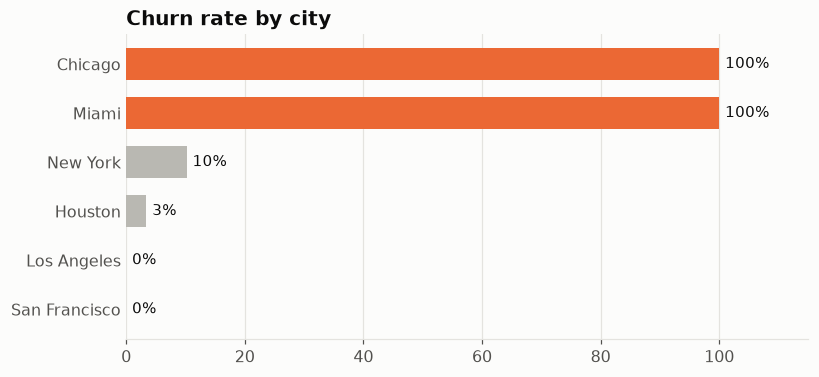

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
style.hbar(ax, city_churn.index, city_churn["churn_rate"], fmt="{:.0f}%", color=ORANGE,
           highlight=set(city_churn.index[city_churn["churn_rate"] > 50]))
ax.set_title("Churn rate by city")
style.save(fig, "churn_by_city")
plt.show()

Each city has exactly one membership tier, and **every customer in Chicago and Miami churned while almost no one elsewhere did**. Satisfaction is just as extreme:

In [8]:
pd.crosstab(df["satisfaction"], df["churn"], margins=True)

churn,0,1,All
satisfaction,,,
Neutral,107,2,109
Satisfied,119,6,125
Unsatisfied,0,116,116
All,226,124,350


Real customer data never looks like this. The dataset is **synthetic**: a handful of customer templates repeated with small variations. A one-line rule matches the model:

In [9]:
rule = df["city"].isin(["Chicago", "Miami"]).astype(int)
print(f"Rule 'customer lives in Chicago or Miami' → churn: accuracy {(rule == y).mean():.1%} on all 350 rows")

Rule 'customer lives in Chicago or Miami' → churn: accuracy 97.7% on all 350 rows


## 4. Honest re-evaluation

Remove duplicates first, then use 5-fold stratified cross-validation (more stable than one 30% split on ~170 rows). Compare against a majority-class baseline and the city rule.

In [10]:
dedup = df.drop(columns="customer_id").drop_duplicates()
Xd = pd.get_dummies(dedup[features], drop_first=True).astype(float)
yd = dedup["churn"]
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

rows = [
    {"setup": "Majority class (always 'stays')", "accuracy": 1 - yd.mean()},
    {"setup": "City rule (Chicago or Miami)", "accuracy": (dedup["city"].isin(["Chicago", "Miami"]).astype(int) == yd).mean()},
]
for name, m in models.items():
    rows.append({"setup": f"{name}, all features", "accuracy": cross_val_score(m, Xd, yd, cv=cv).mean()})
no_location = [c for c in Xd.columns if not c.startswith(("city_", "membership_", "satisfaction_"))]
for name, m in models.items():
    rows.append({"setup": f"{name}, without city / tier / satisfaction",
                 "accuracy": cross_val_score(m, Xd[no_location], yd, cv=cv).mean()})
honest = pd.DataFrame(rows).assign(accuracy=lambda d: (100 * d["accuracy"]).round(1))
print(f"{len(dedup)} unique customers, churn rate {yd.mean():.1%}")
honest

168 unique customers, churn rate 39.9%


,setup,accuracy
0,Majority class (always 'stays'),60.1
1,City rule (Chicago or Miami),95.2
2,"Logistic regression, all features",95.3
3,"Random forest, all features",95.3
4,"Logistic regression, without city / tier / sat...",95.3
5,"Random forest, without city / tier / satisfaction",94.1


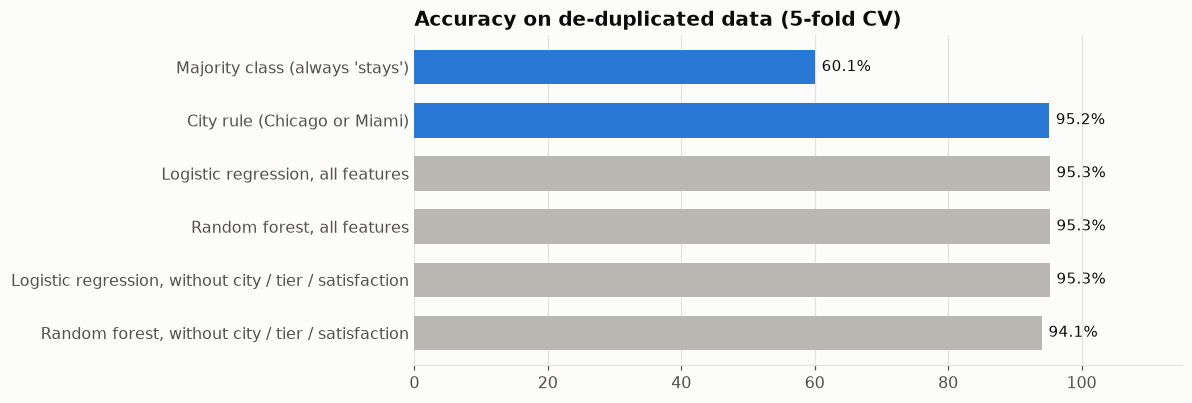

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.9))
style.hbar(ax, honest["setup"], honest["accuracy"], fmt="{:.1f}%",
           highlight={"City rule (Chicago or Miami)", "Majority class (always 'stays')"}, color=BLUE)
ax.set_xlim(0, 115)
ax.set_title("Accuracy on de-duplicated data (5-fold CV)")
style.save(fig, "honest_evaluation")
plt.show()

## Key findings

In [12]:
rf_all = honest.loc[honest["setup"] == "Random forest, all features", "accuracy"].item()
city_acc = honest.loc[honest["setup"] == "City rule (Chicago or Miami)", "accuracy"].item()
print(f"1. Gold members spend the most (${summary.loc['Gold', 'avg_spend']:,.0f} on average vs "
      f"${summary.loc['Bronze', 'avg_spend']:,.0f} for Bronze) and are the most satisfied.")
print(f"2. The ~{100 * max(naive.values()):.0f}% churn accuracy is reproducible but meaningless: {len(df) - n_unique} of {len(df)} rows are duplicates "
      f"({test_rows_seen:.0%} of test rows were already in training), and city alone explains churn.")
print(f"3. A one-line city rule scores {city_acc:.1f}%; the models score {rf_all:.1f}%, so they learned that rule, "
      "not customer behaviour.")
spend = df.groupby("city")["total_spend"].agg(["min", "max"])
print(f"4. Dropping city / tier / satisfaction doesn't help: each city's spend sits in its own narrow band "
      f"(Chicago ${spend.loc['Chicago', 'min']:,.0f}-{spend.loc['Chicago', 'max']:,.0f}, Miami ${spend.loc['Miami', 'min']:,.0f}-"
      f"{spend.loc['Miami', 'max']:,.0f}, ...), so spend alone reveals the city.")
print("5. Lesson: before trusting a high score, check for duplicates, leakage and suspiciously clean patterns, "
      "and always compare against a simple rule. This dataset is fine for practising EDA, not for building a churn model.")

1. Gold members spend the most ($1,311 on average vs $473 for Bronze) and are the most satisfied.
2. The ~98% churn accuracy is reproducible but meaningless: 182 of 350 rows are duplicates (88% of test rows were already in training), and city alone explains churn.
3. A one-line city rule scores 95.2%; the models score 95.3%, so they learned that rule, not customer behaviour.
4. Dropping city / tier / satisfaction doesn't help: each city's spend sits in its own narrow band (Chicago $475-530, Miami $660-730, ...), so spend alone reveals the city.
5. Lesson: before trusting a high score, check for duplicates, leakage and suspiciously clean patterns, and always compare against a simple rule. This dataset is fine for practising EDA, not for building a churn model.
